# Multilevel option pricing

Author: Fred J. Hickernell · MATH 565, Fall 2026

Companion to [Selected Topics: Multilevel Monte Carlo](https://fjhickernell.github.io/MATH565Fall2026/slides/05-selected-topics.html#multilevel-monte-carlo)

Use cheap Asian-option approximations and coupled corrections to estimate an expensive price. See how **point counts differ from work**, compare IID with randomized Sobol' sampling, and separate sampling error from time-discretization bias.

Adapted and extended from QMCPy's [Multilevel (Q)MC for Option Pricing](https://qmcsoftware.org/qmcpy/demos/asian-option-mlqmc/). All comparisons below use the same explicitly specified contract and model. The main experiment holds the finest grid fixed; the optional adaptive algorithms choose their own grids.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fjhickernell/MATH565Fall2026/blob/main/notebooks/performance/MultilevelOptionPricing.ipynb)

Run All with the course `qmcpy` kernel. After changing parameters, rerun from the beginning. Colab uses the course's recorded dependency commits once this notebook is published.

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib, QMCPy, and TeX; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    if shutil.which("latex") is None:
        subprocess.run(
            [
                "apt-get", "-qq", "install", "-y",
                "cm-super", "dvipng", "texlive-latex-extra",
                "texlive-latex-recommended",
            ],
            check=True,
        )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
# Find the course checkout and import its recorded source versions.
search_start = course_checkout if colab else Path.cwd().resolve()
course_root = next((p for p in [search_start, *search_start.parents]
                    if (p / 'course-metadata.yml').is_file()
                    and (p / 'qmcpy/qmcpy').is_dir()), None)
if course_root is None:
    raise RuntimeError('Run from the MATH565Fall2026 checkout or use the Colab setup.')
for dependency in ['classlib', 'qmcpy']:
    sys.path.insert(0, str(course_root / dependency))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qmcpy as qp
import classlib as cl
from IPython.display import display

%matplotlib inline
cl.nbviz.init(use_tex=True)

SEED = 5651103
L = 5                         # Course levels ell=1,...,L; d_ell=2**ell
R = 8                         # Independent Sobol' randomizations per estimate
PILOT_N = 512                 # IID pilot contributions at every level
RQMC_PILOT_SIZES = [32, 64, 128]
WORK_BUDGETS = [2**18, 2**19, 2**20]
TRIALS = 24                   # Fresh whole-estimator repetitions per design
BATCH = 4096                  # Bound memory, including reference computations
REF_N, REF_R = 2**17, 32       # Independent finite-grid numerical reference
REFINE_LEVELS = list(range(1, L+3))
REFINE_N, REFINE_R = 2**12, 16
RUN_CONTINUATION = False      # Optional final section; True runs all four solvers

MODEL = dict(option='ASIAN', call_put='CALL', start_price=100.,
             strike_price=100., interest_rate=.05, volatility=.2,
             t_final=1., asian_mean='ARITHMETIC',
             asian_mean_quadrature_rule='TRAPEZOIDAL',
             decomp_type='BrownianBridge', d_coarsest=2)
assert L >= 2 and R >= 2 and TRIALS >= 2
assert not RUN_CONTINUATION or R >= 4
assert all(n > 0 and n & (n-1) == 0 for n in RQMC_PILOT_SIZES + [REF_N, REFINE_N, BATCH])
levels = np.arange(1, L+1)
dimensions = 2**levels
# Transparent time-step work proxy, not measured runtime:
# fine-grid work plus coarse payoff accumulation for a correction.
level_cost = dimensions.astype(float) + np.r_[0, dimensions[:-1]]
fine_cost = float(dimensions[-1])

def stream(*labels):
    return np.random.SeedSequence([SEED, *map(int, labels)])

print(f'QMCPy {qp.__version__}; source: {Path(qp.__file__).resolve()}')
print(f'Fixed target: {dimensions[-1]} time steps; {R} independent Sobol\' runs per estimate')
display(pd.DataFrame([MODEL]).drop(columns=['option', 'call_put', 'd_coarsest']))

QMCPy 2.4; source: /Users/fredjhickernell/SoftwareRepositories/MATH565Fall2026/qmcpy/qmcpy/__init__.py
Fixed target: 32 time steps; 8 independent Sobol' runs per estimate


,start_price,strike_price,interest_rate,volatility,t_final,asian_mean,asian_mean_quadrature_rule,decomp_type
0,100.0,100.0,0.05,0.2,1.0,ARITHMETIC,TRAPEZOIDAL,BrownianBridge


## 1. One model, a hierarchy of price approximations

Under the risk-neutral model,
\begin{align*}
S(t)&=S_0\exp\{(r-\sigma^2/2)t+\sigma B(t)\},\\
A_d&=\frac{S_0/2+\sum_{j=1}^{d-1}S(jT/d)+S(T)/2}{d},\\
P_d&=e^{-rT}(A_d-K)_+,
\qquad \mu_d=\mathbb E(P_d).
\end{align*}
Here $A_d$ approximates the **continuous time average** $T^{-1}\int_0^T S(t)\,\mathrm dt$. Increasing $d$ improves that approximation. This differs from the fixed weekly monitoring in the earlier Asian-option variance-reduction notebook.

Use $d_\ell=2^\ell$, $\ell=1,\ldots,L$:
\begin{align*}
Y_1&=P_{d_1}, &Y_\ell&=P_{d_\ell}-P_{d_{\ell-1}},\\
\mu_{d_L}&=\sum_{\ell=1}^L\mathbb E(Y_\ell),
&\mu&=\lim_{d\to\infty}\mu_d.
\end{align*}

The main experiment estimates the **finite target** $\mu_{d_L}$. Its integration error is separate from $b_L=\mu-\mu_{d_L}$. An arithmetic Asian option has no exact price supplied here.

**Sampling map:** QMCPy generates uniform inputs $\boldsymbol U$, transforms them into a Brownian path $\boldsymbol X=\boldsymbol T(\boldsymbol U)$, then evaluates $Y_\ell=f_\ell(\boldsymbol X)$. Brownian bridge changes the coordinate construction, not the target Brownian law. Sample indices start at zero; course levels start at one. QMCPy's `level` argument starts at zero, so code passes `ell-1`.

The Sobol' generator uses Gray ordering to evaluate bounded chunks. Every complete run still uses a power-of-two prefix; chunk boundaries do not create new randomizations or separate estimates.

In [3]:
def sampler(d, method, seed):
    if method == 'IID':
        return qp.IIDStdUniform(int(d), seed=seed)
    return qp.DigitalNetB2(int(d), seed=seed, randomize='LMS DS',
                          order='GRAY')


def option(ell, method, seed, correction=True):
    return qp.FinancialOption(sampler(2**int(ell), method, seed),
                              level=int(ell)-1 if correction else None, **MODEL)


def contributions(ell, n, method, seed, correction=True):
    """Complete generation, Brownian transformation, and payoff evaluation."""
    integrand = option(ell, method, seed, correction)
    for start in range(0, int(n), BATCH):
        y = integrand(n_min=start, n_max=min(start+BATCH, int(n)), warn=False)
        yield y[1]-y[0] if correction else y


def estimate(ell, n, method, seed, correction=True):
    total = sum(np.sum(y, dtype=np.float64)
                for y in contributions(ell, n, method, seed, correction))
    return float(total / n)


def replicated_means(ell, n, reps, labels, correction=True):
    return np.array([estimate(ell, n, 'Sobol', stream(*labels, rep), correction)
                     for rep in range(reps)])


def trap_payoff(stock):
    average = (MODEL['start_price']/2 + stock[..., :-1].sum(axis=-1)
               + stock[..., -1]/2) / stock.shape[-1]
    return np.exp(-MODEL['interest_rate']*MODEL['t_final']) * np.maximum(average-MODEL['strike_price'], 0)

# Native FinancialOption agrees with the displayed trapezoidal payoff.
check = option(3, 'IID', stream(0))
stock = check.true_measure(16)
expected = np.stack([trap_payoff(stock[..., 1::2]), trap_payoff(stock)])
np.testing.assert_allclose(check.g(stock), expected, rtol=1e-13, atol=1e-13)
base = option(1, 'IID', stream(0, 1))
np.testing.assert_array_equal(base.g(base.true_measure(4))[0], np.zeros(4))
print('Payoff convention and base-level zero coarse contribution verified')

Payoff convention and base-level zero coarse contribution verified


## 2. Couple the driving Brownian path

With $2m$ fine increments over $[0,T]$, form
\begin{align*}
\Delta W_i^{\mathrm f}&\sim\operatorname{Norm}(0,T/(2m)),
&&i=0,\ldots,2m-1,\\
\Delta W_j^{\mathrm c}&=\Delta W_{2j}^{\mathrm f}+\Delta W_{2j+1}^{\mathrm f},
&&j=0,\ldots,m-1.
\end{align*}
The coarse Brownian values equal every other fine Brownian value. Price both discretizations from this shared path; do not generate an unrelated coarse path for the correction. Coarse and fine **price approximations** can still differ.

Use a separate independent sample set for each level mean. For randomized Sobol', whole randomizations are independent between levels; points within one run are dependent. The earlier $f_d(\boldsymbol X_{1:d})$ notation assumes compatible hierarchical inputs: coarsening is not truncating the chronological fine-increment vector.

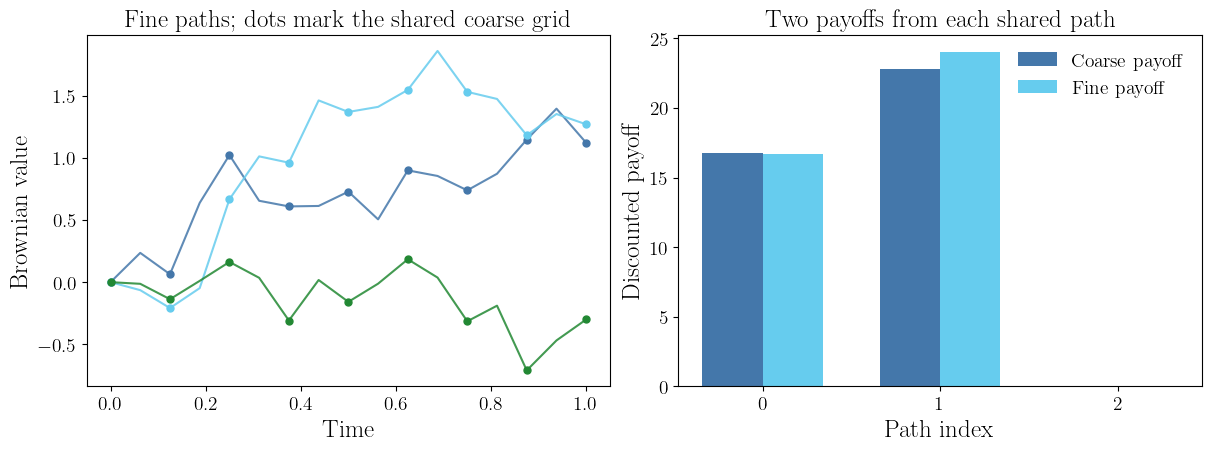

,coarse,fine,correction
path,,,
0,16.761720,16.724970,-0.036749
1,22.770361,24.048464,1.278103
2,0.000000,0.000000,0.000000


In [4]:
d_demo = 16
brownian = qp.BrownianMotion(qp.IIDStdUniform(d_demo, seed=stream(1)),
                             t_final=MODEL['t_final'], decomp_type='BrownianBridge')
w_fine = brownian(3)
dw_fine = np.diff(np.c_[np.zeros(3), w_fine], axis=1)
dw_coarse = dw_fine.reshape(3, d_demo//2, 2).sum(axis=-1)
w_coarse = np.cumsum(dw_coarse, axis=1)
np.testing.assert_allclose(w_coarse, w_fine[:, 1::2], rtol=1e-12, atol=1e-12)
t_fine = np.linspace(0, MODEL['t_final'], d_demo+1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for i in range(3):
    line, = axes[0].plot(t_fine, np.r_[0, w_fine[i]], alpha=.85)
    axes[0].plot(t_fine[::2], np.r_[0, w_coarse[i]], 'o', color=line.get_color(), markersize=5)
axes[0].set(xlabel='Time', ylabel='Brownian value', title='Fine paths; dots mark the shared coarse grid')
stock = MODEL['start_price'] * np.exp((MODEL['interest_rate']-MODEL['volatility']**2/2)
        * t_fine[1:] + MODEL['volatility']*w_fine)
fine_payoff, coarse_payoff = trap_payoff(stock), trap_payoff(stock[:, 1::2])
axes[1].bar(np.arange(3)-.17, coarse_payoff, width=.34, label='Coarse payoff')
axes[1].bar(np.arange(3)+.17, fine_payoff, width=.34, label='Fine payoff')
axes[1].set(xlabel='Path index', ylabel='Discounted payoff', title='Two payoffs from each shared path', xticks=range(3))
axes[1].legend()
plt.show()
display(pd.DataFrame({'path':range(3), 'coarse':coarse_payoff, 'fine':fine_payoff,
                      'correction':fine_payoff-coarse_payoff}).set_index('path'))

## 3. Pilot the error and work at each level

For IID sampling, $V_\ell=\operatorname{var}(Y_\ell)$ and
\[
\operatorname{var}(\widehat\mu)=\sum_{\ell=1}^L V_\ell/n_\ell.
\]
Compare a coupled difference with a difference formed from **independent** fine and coarse paths. Their means agree, but their variances need not.

The work proxy is $c_1=d_1$ and $c_\ell=d_\ell+d_{\ell-1}$ for $\ell>1$, counting fine-grid processing and coarse payoff accumulation. It is an illustrative time-step model, not measured total runtime. The timings below include sampler construction, generation, Brownian transformation, and both payoff evaluations. Setup makes these small-batch timings imperfect per-point predictors.

We charge pilot proxy work to every design that uses the pilot. We freeze the resulting allocations and use fresh final samples; pilot data do not enter final estimates.

,steps,correction_mean,coupled_variance,independent_variance,proxy_cost,complete_batch_seconds,seconds_per_contribution
level,,,,,,,
1,2,5.929606,62.905816,56.791129,2.0,0.001315,2.568604e-06
2,4,0.182094,4.012162,115.530283,6.0,0.000321,6.272773e-07
3,8,0.042434,0.932926,134.756221,12.0,0.000320,6.246758e-07
4,16,0.026729,0.261393,120.383308,24.0,0.000428,8.363438e-07
5,32,0.014896,0.056123,133.404277,48.0,0.001273,2.486002e-06


Allocation pilot: 47,104 proxy work; pilot: 0.004 sec; complete diagnostic section: 0.009 sec


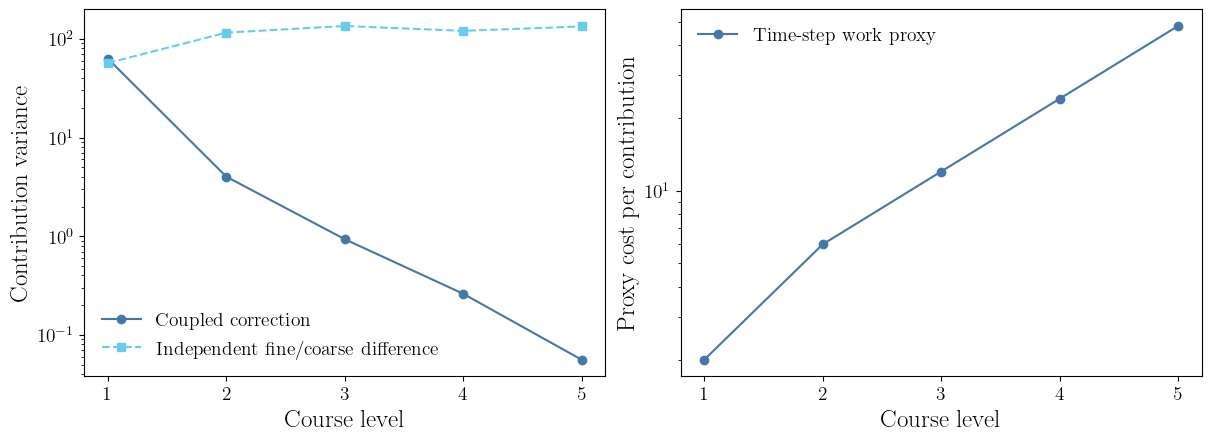

In [5]:
pilot_started = time.perf_counter()
pilot_variance, diagnostic_rows = [], []
for ell, d, cost in zip(levels, dimensions, level_cost):
    started = time.perf_counter()
    values = np.concatenate(list(contributions(ell, PILOT_N, 'IID', stream(2, ell))))
    elapsed = time.perf_counter()-started
    variance = values.var(ddof=1)
    pilot_variance.append(variance)
    direct_values = np.concatenate(list(contributions(ell, PILOT_N, 'IID', stream(3, ell), False)))
    if ell > 1:
        coarse_values = np.concatenate(list(contributions(ell-1, PILOT_N, 'IID', stream(4, ell), False)))
        independent_variance = direct_values.var(ddof=1)+coarse_values.var(ddof=1)
    else:
        independent_variance = direct_values.var(ddof=1)
    diagnostic_rows.append(dict(level=ell, steps=d, correction_mean=values.mean(),
                                coupled_variance=variance, independent_variance=independent_variance,
                                proxy_cost=cost, complete_batch_seconds=elapsed,
                                seconds_per_contribution=elapsed/PILOT_N))
pilot_variance = np.array(pilot_variance)
IID_PILOT_WORK = float(PILOT_N*level_cost.sum())
IID_SECTION_SECONDS = time.perf_counter()-pilot_started
# Additional independent-difference draws are explanatory diagnostics, not used for allocation.
diag = pd.DataFrame(diagnostic_rows).set_index('level')
IID_PILOT_SECONDS = float(diag.complete_batch_seconds.sum())
display(diag)
print(f'Allocation pilot: {IID_PILOT_WORK:,.0f} proxy work; pilot: {IID_PILOT_SECONDS:.3f} sec; complete diagnostic section: {IID_SECTION_SECONDS:.3f} sec')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
axes[0].semilogy(levels, diag.coupled_variance, 'o-', label='Coupled correction')
axes[0].semilogy(levels, diag.independent_variance, 's--', label='Independent fine/coarse difference')
axes[0].set(xlabel='Course level', ylabel='Contribution variance', xticks=levels)
axes[0].legend()
axes[1].semilogy(levels, diag.proxy_cost, 'o-', label='Time-step work proxy')
axes[1].set(xlabel='Course level', ylabel='Proxy cost per contribution', xticks=levels)
axes[1].legend()
plt.show()

## 4. Equal point counts, equal work, or optimal IID allocation?

At final-sample work $C$, the IID continuous optimum has
\[
w_\ell=\sqrt{V_\ell/c_\ell},\qquad
n_\ell=\frac{Cw_\ell}{\sum_k c_kw_k}.
\]
Equal point counts and equal work shares are different designs. A small correction can receive fewer points without receiving negligible work. The optimal design uses independent pilot variances; equal-count and equal-work designs need no allocation pilot. Each design receives the same total budget, with pilot work deducted only for the optimal design. All designs use integer rounding; the MSE column is a **pilot prediction**, not an observed error or accuracy certificate.

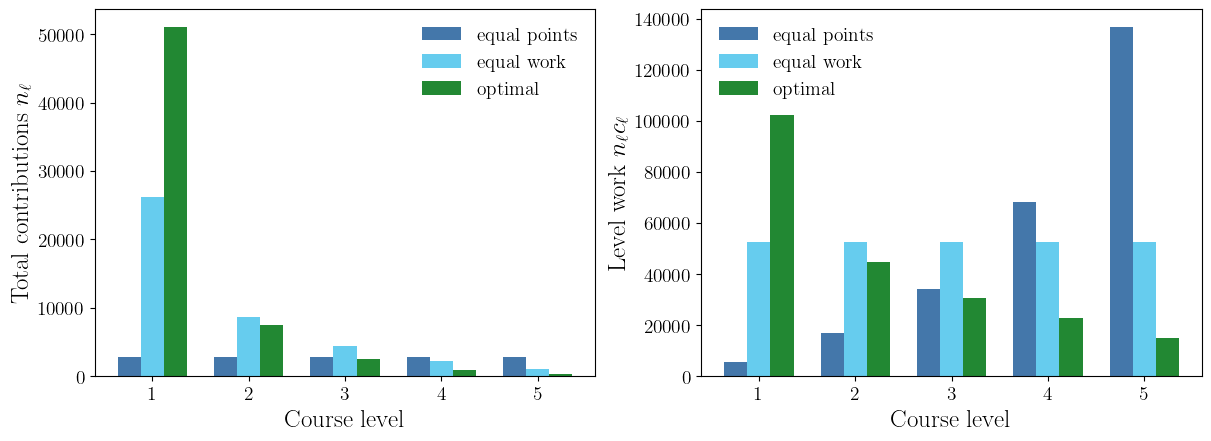

,final_work,pilot_work,predicted_MSE
design,,,
equal points,262108.0,0.0,0.023927
equal work,262116.0,0.0,0.003243
optimal,215040.0,47104.0,0.002593


In [6]:
def iid_allocation(budget, kind='optimal'):
    if kind == 'equal points':
        return np.full(L, max(1, int(budget//level_cost.sum())))
    if kind == 'equal work':
        return np.maximum(1, np.floor(budget/(L*level_cost))).astype(int)
    weights = np.sqrt(pilot_variance/level_cost)
    continuous = budget*weights / np.dot(level_cost, weights)
    counts = np.maximum(1, np.floor(continuous)).astype(int)
    if np.dot(counts, level_cost) > budget:
        raise ValueError('Budget cannot fund one contribution per level')
    # Spend the small rounding remainder where it reduces the variance model most.
    while True:
        affordable = level_cost <= budget-np.dot(counts, level_cost)
        if not affordable.any(): break
        gain = pilot_variance/(counts*(counts+1)*level_cost)
        counts[np.argmax(np.where(affordable, gain, -np.inf))] += 1
    return counts

allocation_budget = WORK_BUDGETS[0]
allocations = {kind:iid_allocation(allocation_budget-(IID_PILOT_WORK if kind=='optimal' else 0), kind)
               for kind in ['equal points','equal work','optimal']}
summary = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), constrained_layout=True)
for j,(kind,counts) in enumerate(allocations.items()):
    offset=(j-1)*.24
    axes[0].bar(levels+offset, counts, width=.24, label=kind)
    axes[1].bar(levels+offset, counts*level_cost, width=.24, label=kind)
    summary.append(dict(design=kind, final_work=np.dot(counts,level_cost),
                        pilot_work=IID_PILOT_WORK if kind=='optimal' else 0, predicted_MSE=np.sum(pilot_variance/counts)))
axes[0].set(xlabel='Course level', ylabel=r'Total contributions $n_\ell$', xticks=levels)
axes[1].set(xlabel='Course level', ylabel=r'Level work $n_\ell c_\ell$', xticks=levels)
axes[0].legend(); axes[1].legend()
plt.show()
display(pd.DataFrame(summary).set_index('design'))

## 5. Randomized Sobol' needs a different allocation pilot

For $R$ independent randomizations, let $N_\ell$ be the points per run and $n_\ell=RN_\ell$ the **total** level contributions. If $M_{\ell,r}$ is the mean from one run, estimate the variance of their reported average by
\[
\widehat v_\ell(n_\ell)=\frac{\operatorname{var}_{\mathrm{sample}}(M_{\ell,0},\ldots,M_{\ell,R-1})}{R}.
\]
An IID output variance does not give this quantity. Hold $R$ fixed and pilot several $N$ values. Fit a common positive decay power in $v_\ell(n)\approx A_\ell^2 n^{-2p}$; then use $w_\ell=(A_\ell^2/c_\ell)^{1/(2p+1)}$.

The fitted rate is a noisy planning model. It does not prove a convergence order or justify an adaptive stopping rule. Powers-of-two rounding changes the ideal allocation. A fresh independent randomization is used for every level and every final run.

Common fitted p=0.900; planning model only
RQMC pilot: 164,864 proxy work; 0.071 sec


,individual_fitted_p,fitted_A_squared
level,,
1,1.062636,77.427017
2,0.900078,41.883621
3,0.714272,16.026588
4,0.567488,13.688627
5,0.953401,2.407079


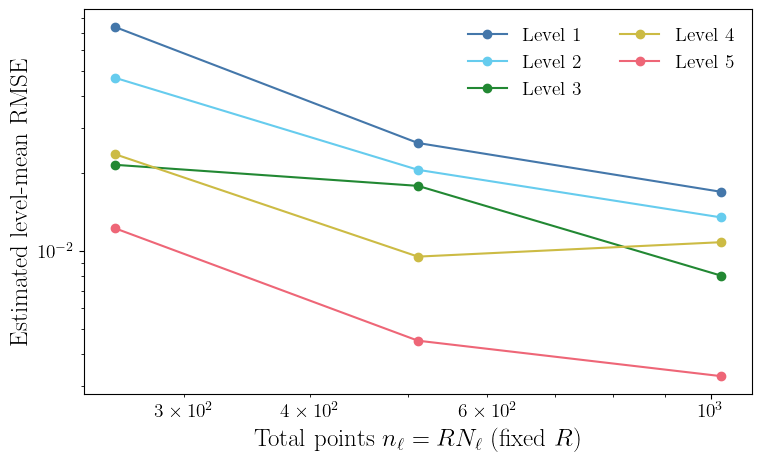

In [7]:
rqmc_pilot_started = time.perf_counter()
pilot_run_variances = np.empty((L, len(RQMC_PILOT_SIZES)))
for k,ell in enumerate(levels):
    for j,n in enumerate(RQMC_PILOT_SIZES):
        means = replicated_means(ell,n,R,(5,ell,j))
        pilot_run_variances[k,j] = means.var(ddof=1)/R
assert np.all(pilot_run_variances > 0)
total_pilot_counts = R*np.array(RQMC_PILOT_SIZES)
rate_by_level = np.array([-np.polyfit(np.log(total_pilot_counts),np.log(v),1)[0]/2
                          for v in pilot_run_variances])
p_rqmc = float(np.median(rate_by_level))
if p_rqmc <= 0:
    raise RuntimeError('Pilot does not support a positive common rate; increase pilot sizes/replications')
amplitude_squared = np.exp(np.mean(np.log(pilot_run_variances)
                                   + 2*p_rqmc*np.log(total_pilot_counts), axis=1))
RQMC_PILOT_WORK = float(total_pilot_counts.sum()*level_cost.sum())
RQMC_PILOT_SECONDS = time.perf_counter()-rqmc_pilot_started
print(f'Common fitted p={p_rqmc:.3f}; planning model only')
print(f'RQMC pilot: {RQMC_PILOT_WORK:,.0f} proxy work; {RQMC_PILOT_SECONDS:.3f} sec')
display(pd.DataFrame({'level':levels, 'individual_fitted_p':rate_by_level,
                      'fitted_A_squared':amplitude_squared}).set_index('level'))
fig, ax = plt.subplots(figsize=(7.5,4.5), constrained_layout=True)
for ell,variances in zip(levels,pilot_run_variances):
    ax.loglog(total_pilot_counts, np.sqrt(variances), 'o-',label=f'Level {ell}')
ax.set(xlabel=r'Total points $n_\ell=RN_\ell$ (fixed $R$)', ylabel='Estimated level-mean RMSE')
ax.legend(ncol=2)
plt.show()

def rqmc_allocation(budget):
    weights=(amplitude_squared/level_cost)**(1/(2*p_rqmc+1))
    continuous=budget*weights/np.dot(weights,level_cost)
    per_run=np.maximum(8,2**np.floor(np.log2(np.maximum(continuous/R,1)))).astype(int)
    if np.dot(R*per_run,level_cost)>budget:
        raise ValueError('Increase budget to fund the minimum Sobol designs')
    while True:
        counts=R*per_run
        added_work=counts*level_cost
        affordable=added_work <= budget-np.dot(counts,level_cost)
        if not affordable.any(): break
        gain=amplitude_squared*counts**(-2*p_rqmc)*(1-2**(-2*p_rqmc))/added_work
        per_run[np.argmax(np.where(affordable,gain,-np.inf))] *= 2
    return per_run

## 6. Independent numerical reference for the finite target

Use many independent scrambled Sobol' runs at the **same finest grid** $d_L$. Report their average and estimated standard error. This is a numerical reference, not an exact value or a reference for the continuous-time limit.

For independent estimates $\widehat\mu$ and $\widehat\mu_{\mathrm{ref}}$, the expected squared discrepancy contains both variances. Thus reference uncertainty must be small compared with the displayed RMSE. We report it rather than silently subtracting a noisy variance estimate. Reference generation is validation work, excluded from estimator work budgets but included in total notebook execution time.

In [8]:
reference_started=time.perf_counter()
reference_runs=replicated_means(L, REF_N, REF_R, (6,), correction=False)
reference=float(reference_runs.mean())
reference_se=float(reference_runs.std(ddof=1)/np.sqrt(REF_R))
print(f'Finite-grid numerical reference mu_dL: {reference:.8f}')
print(f'Estimated reference SE: {reference_se:.3g}; {REF_R} runs of {REF_N:,} points')
print(f'Reference time: {time.perf_counter()-reference_started:.2f} sec (validation, not estimator work)')

Finite-grid numerical reference mu_dL: 5.76259727
Estimated reference SE: 7.63e-05; 32 runs of 131,072 points
Reference time: 2.71 sec (validation, not estimator work)


## 7. Compare complete estimators at the same work budgets

Every method targets $\mu_{d_L}$ and receives the same **maximum proxy-work budget**, including any allocation pilot. Direct estimators need no allocation pilot. Unused work from powers-of-two rounding is recorded; the horizontal axis shows actual charged work.

For each frozen design, run `TRIALS` independent whole estimators. The reported empirical RMSE is the root mean square discrepancy from the independent numerical reference. It estimates sampling error, with reference uncertainty and a finite number of trials. It is not a guaranteed error bound.

The measured times include construction, generation, transforms, and payoff evaluation. Add the measured allocation-pilot time to each hypothetical complete run: this deliberately charges the pilot once per run rather than amortizing it over the repeated experiment. Extra teaching diagnostics and numerical references are reported separately. Proxy work and seconds answer different cost questions.

,method,budget,charged_work,pilot_work,unused_work,empirical_RMSE,complete_seconds
0,Direct IID,262144,262144.0,0.0,0.0,0.077804,0.0069
1,Direct randomized Sobol',262144,262144.0,0.0,0.0,0.003928,0.0128
2,MLMC equal points,262144,262108.0,0.0,36.0,0.155461,0.0065
3,MLMC optimal,262144,262144.0,47104.0,0.0,0.043320,0.0100
4,MLQMC pilot allocation,262144,259072.0,164864.0,3072.0,0.015261,0.0957
5,Direct IID,524288,524288.0,0.0,0.0,0.064804,0.0129
6,Direct randomized Sobol',524288,524288.0,0.0,0.0,0.001777,0.0179
7,MLMC equal points,524288,524216.0,0.0,72.0,0.097841,0.0100
8,MLMC optimal,524288,524288.0,47104.0,0.0,0.030531,0.0139
9,MLQMC pilot allocation,524288,492544.0,164864.0,31744.0,0.006455,0.0974


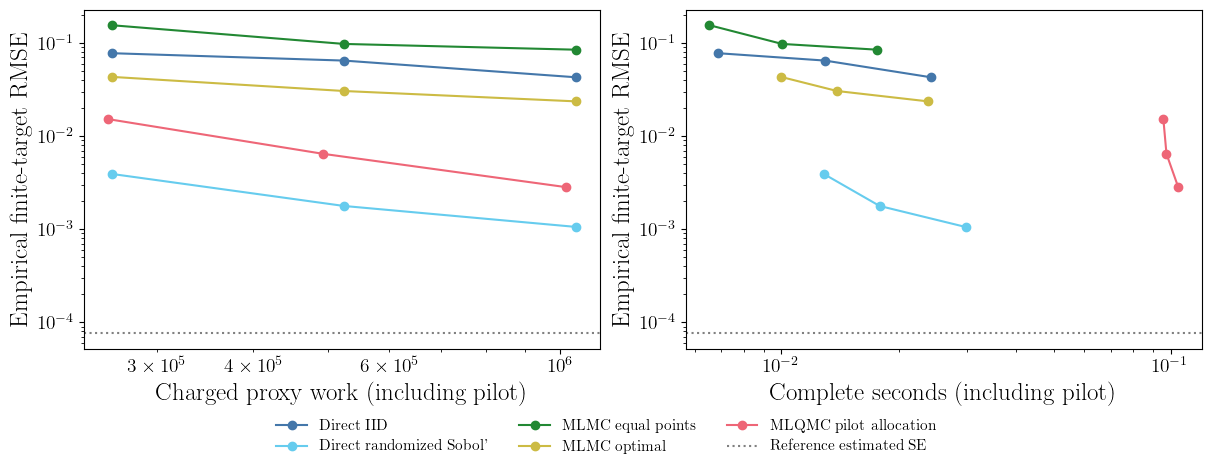

Reference SE / smallest empirical RMSE: 0.072
With only a few budgets and finite trials, these curves illustrate behavior, not asymptotic-rate proofs


In [9]:
def ml_estimate(counts, method, labels):
    total=0.
    for ell,count in zip(levels,counts):
        if method=='IID':
            total+=estimate(ell,int(count),'IID',stream(*labels,ell))
        else:
            total+=replicated_means(ell,int(count),R,(*labels,ell)).mean()
    return total

records=[]
for bi,budget in enumerate(WORK_BUDGETS):
    n_iid=int(budget//fine_cost)
    n_sobol=2**int(np.floor(np.log2(budget/(R*fine_cost))))
    equal=iid_allocation(budget,'equal points')
    optimal=iid_allocation(budget-IID_PILOT_WORK)
    rqmc=rqmc_allocation(budget-RQMC_PILOT_WORK)
    designs=[
      ('Direct IID',np.array([n_iid]),0.,0.,n_iid*fine_cost),
      ("Direct randomized Sobol'",np.array([n_sobol]),0.,0.,R*n_sobol*fine_cost),
      ('MLMC equal points',equal,0.,0.,np.dot(equal,level_cost)),
      ('MLMC optimal',optimal,IID_PILOT_WORK,IID_PILOT_SECONDS,np.dot(optimal,level_cost)),
      ('MLQMC pilot allocation',rqmc,RQMC_PILOT_WORK,RQMC_PILOT_SECONDS,np.dot(R*rqmc,level_cost))]
    for mi,(name,counts,pilot_work,pilot_seconds,final_work) in enumerate(designs):
        estimates=[]; durations=[]
        for trial in range(TRIALS):
            labels=(7,bi,mi,trial)
            started=time.perf_counter()
            if name=='Direct IID': result=estimate(L,n_iid,'IID',stream(*labels),False)
            elif name.startswith('Direct randomized'):
                result=replicated_means(L,n_sobol,R,labels,False).mean()
            else: result=ml_estimate(counts,'Sobol' if name.startswith('MLQMC') else 'IID',labels)
            estimates.append(result);durations.append(time.perf_counter()-started)
        estimates=np.array(estimates)
        discrepancy_rmse=float(np.sqrt(np.mean((estimates-reference)**2)))
        records.append(dict(method=name, budget=budget, pilot_work=pilot_work,
                            final_work=final_work, charged_work=final_work+pilot_work,
                            unused_work=budget-final_work-pilot_work,
                            empirical_RMSE=discrepancy_rmse,
                            trial_SD=estimates.std(ddof=1), mean_estimate=estimates.mean(),
                            complete_seconds=np.mean(durations)+pilot_seconds))
results=pd.DataFrame(records)
display(results[['method','budget','charged_work','pilot_work','unused_work',
                 'empirical_RMSE','complete_seconds']].round({'empirical_RMSE':6,'complete_seconds':4}))
fig,axes=plt.subplots(1,2,figsize=(12,4.6),constrained_layout=True)
for name,frame in results.groupby('method',sort=False):
    axes[0].loglog(frame.charged_work,frame.empirical_RMSE,'o-',label=name)
    axes[1].loglog(frame.complete_seconds,frame.empirical_RMSE,'o-',label=name)
for ax in axes:
    ax.axhline(reference_se,color='gray',linestyle=':',label='Reference estimated SE')
    ax.set_ylabel('Empirical finite-target RMSE')
axes[0].set_xlabel('Charged proxy work (including pilot)')
axes[1].set_xlabel('Complete seconds (including pilot)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=11)
plt.show()
print(f'Reference SE / smallest empirical RMSE: {reference_se/results.empirical_RMSE.min():.3f}')
print('With only a few budgets and finite trials, these curves illustrate behavior, not asymptotic-rate proofs')

### Read the comparison before choosing a method

For the default modest finest grid, direct randomized Sobol' can outperform MLQMC: pilot overhead and an already inexpensive fine model can outweigh the multilevel benefit. Equal-point MLMC can also be worse than direct IID. The value of coupling depends on using an effective allocation and on the original fine problem being sufficiently expensive. These experiments do not establish a universal method ranking.

### Inspect the MLQMC allocation

The pilot-derived Sobol' counts are **per independent run**. Multiply by $R$ before comparing total contributions or level work with IID counts. A common fitted rate is an approximation; if individual levels have different behavior, measured marginal gains or level-specific rates can be preferable.

,IID_total_points,Sobol_points_per_run,Sobol_total_points,IID_level_work,Sobol_level_work
level,,,,,
1,237843,4096,32768,475686.0,65536.0
2,34679,4096,32768,208074.0,196608.0
3,11824,2048,16384,141888.0,196608.0
4,4426,1024,8192,106224.0,196608.0
5,1450,512,4096,69600.0,196608.0


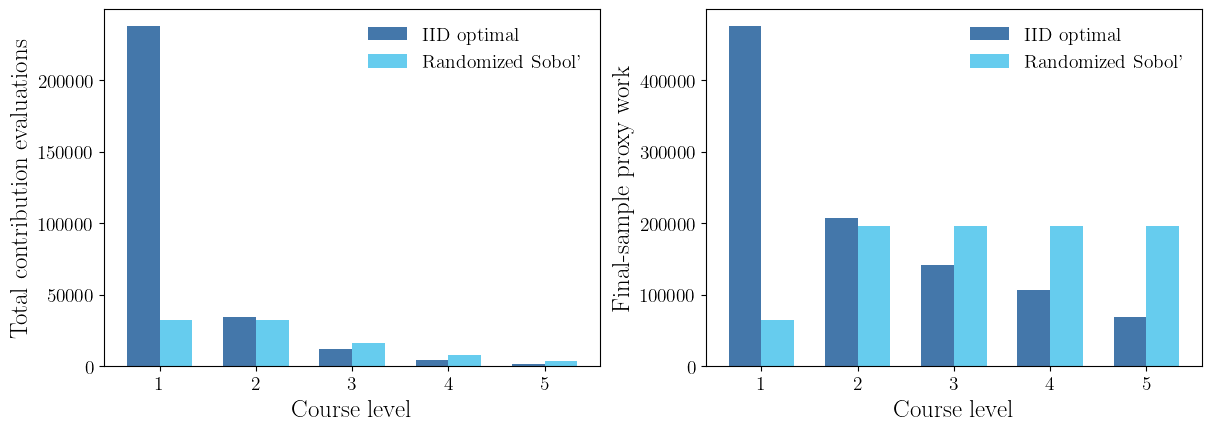

In [10]:
budget=WORK_BUDGETS[-1]
counts_iid=iid_allocation(budget-IID_PILOT_WORK)
counts_per_run=rqmc_allocation(budget-RQMC_PILOT_WORK)
display(pd.DataFrame({'level':levels, 'IID_total_points':counts_iid,
                      'Sobol_points_per_run':counts_per_run,
                      'Sobol_total_points':R*counts_per_run,
                      'IID_level_work':counts_iid*level_cost,
                      'Sobol_level_work':R*counts_per_run*level_cost}).set_index('level'))
fig,axes=plt.subplots(1,2,figsize=(12,4.2),constrained_layout=True)
for offset,name,counts in [(-.17,'IID optimal',counts_iid),(.17,"Randomized Sobol'",R*counts_per_run)]:
    axes[0].bar(levels+offset,counts,width=.34,label=name)
    axes[1].bar(levels+offset,counts*level_cost,width=.34,label=name)
axes[0].set(xlabel='Course level',ylabel='Total contribution evaluations',xticks=levels)
axes[1].set(xlabel='Course level',ylabel='Final-sample proxy work',xticks=levels)
axes[0].legend();axes[1].legend()
plt.show()

## 8. Sampling error is not continuous-limit bias

Use the same parameters on grids both coarser and finer than $d_L$. Estimate adjacent correction means from independent randomized Sobol' runs, and add or subtract them from the independent $d_L$ reference. The coarse grids make the resolution effect visible; refinements beyond $d_L$ probe what remains.

For an unbiased random estimate of the finest finite price,
\[
\operatorname{MSE}(\widehat\mu;\mu)
=b_L^2+\operatorname{var}(\widehat\mu).
\]
More samples at fixed $L$ reduce variance but leave $b_L$ unchanged. A small last correction is only a diagnostic: it does not bound the entire uncomputed tail. Estimated standard errors below describe randomization uncertainty, not an unknown discretization-bias bound.

Plot bars are two estimated randomization standard errors, not certified intervals. The rows share the numerical reference and some correction estimates, so the plotted errors are correlated across resolutions.

,level,steps,price_estimate,randomization_SE,correction_mean,correction_SE
0,1,2,5.637960,0.000984,NaN,NaN
1,2,4,5.732281,0.000764,0.094322,0.000620
2,3,8,5.754701,0.000560,0.022420,0.000520
3,4,16,5.761166,0.000238,0.006465,0.000507
4,5,32,5.762597,0.000076,0.001431,0.000225
5,6,64,5.762787,0.000153,0.000190,0.000132
6,7,128,5.762917,0.000178,0.000130,0.000092


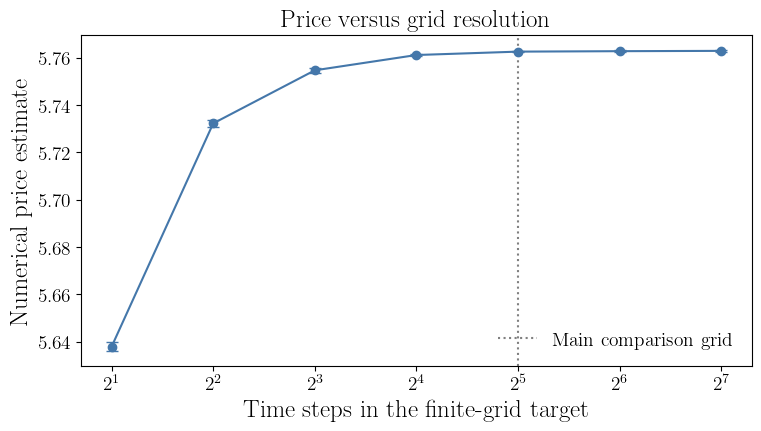

Refinement diagnostic time: 5.28 sec


In [11]:
bias_started=time.perf_counter()
correction_diagnostics={}
for ell in REFINE_LEVELS:
    if ell <= 1: continue
    runs=replicated_means(ell,REFINE_N,REFINE_R,(8,ell))
    correction_diagnostics[ell]=(float(runs.mean()),float(runs.std(ddof=1)/np.sqrt(REFINE_R)))
prices={L:(reference,reference_se**2)}
for ell in range(L,1,-1):
    mean,se=correction_diagnostics[ell]
    prices[ell-1]=(prices[ell][0]-mean,prices[ell][1]+se**2)
for ell in range(L+1,max(REFINE_LEVELS)+1):
    mean,se=correction_diagnostics[ell]
    prices[ell]=(prices[ell-1][0]+mean,prices[ell-1][1]+se**2)
bias_rows=[]
for ell in REFINE_LEVELS:
    mean,se=correction_diagnostics.get(ell,(np.nan,np.nan))
    price,variance=prices[ell]
    bias_rows.append(dict(level=ell,steps=2**ell,price_estimate=price,
                          randomization_SE=np.sqrt(variance),correction_mean=mean,correction_SE=se))
bias_table=pd.DataFrame(bias_rows)
display(bias_table)
fig,ax=plt.subplots(figsize=(7.5,4.2),constrained_layout=True)
ax.errorbar(bias_table.steps,bias_table.price_estimate,
            yerr=2*bias_table.randomization_SE,fmt='o-',capsize=4)
ax.axvline(2**L,color='gray',linestyle=':',label='Main comparison grid')
ax.set_xscale('log',base=2)
ax.set(xlabel='Time steps in the finite-grid target',ylabel='Numerical price estimate',
       title='Price versus grid resolution')
ax.legend()
plt.show()
print(f'Refinement diagnostic time: {time.perf_counter()-bias_started:.2f} sec')

## 9. Optional: QMCPy's adaptive and continuation algorithms

Set `RUN_CONTINUATION=True` in the parameter cell to run this section. `CubMLMC` and `CubMLQMC` adapt the allocation **and finest level**, using estimated bias. Their continuation variants first solve looser problems to learn allocation and refinement behavior.

These runs target the continuous-limit price under an estimated bias model; they are not part of the fixed-$L$ benchmark. Request `rmse_tol` explicitly. It is an algorithmic target, not a verified finite-sample RMSE guarantee. Fresh samplers keep runs independent. The sample/level limits bound the demonstration; inspect warnings before claiming a tolerance was achieved.

`data.n_level` counts IID contributions for MLMC, but points **per replication** for MLQMC. QMCPy's internal refinement level starts at zero, whereas the course's levels start at one.

In [12]:
if RUN_CONTINUATION:
    import warnings
    adaptive_rows=[]
    for i,name in enumerate(['CubMLMC','CubMLMCCont','CubMLQMC','CubMLQMCCont']):
        use_qmc='QMC' in name
        distribution=(qp.DigitalNetB2(seed=stream(9,i),replications=R,randomize='LMS DS')
                      if use_qmc else qp.IIDStdUniform(seed=stream(9,i)))
        integrand=qp.FinancialOption(distribution,**MODEL)
        stopper=getattr(qp,name)(integrand,rmse_tol=.03,n_init=128,
                                 n_limit=2**20,levels_max=7)
        started=time.perf_counter()
        with warnings.catch_warnings(record=True) as notices:
            solution,data=stopper.integrate()
        seconds=time.perf_counter()-started
        totals=np.array(data.n_level)*(R if use_qmc else 1)
        adaptive_rows.append(dict(method=name,price=float(solution),
                                  level_count=len(totals),total_contributions=int(totals.sum()),
                                  complete_seconds=seconds,
                                  warnings='; '.join(str(w.message) for w in notices)))
        print(name, 'total contributions by level:',totals)
    display(pd.DataFrame(adaptive_rows).set_index('method'))
else:
    print('Optional adaptive/continuation comparison skipped; set RUN_CONTINUATION=True and Run All to include it')

Optional adaptive/continuation comparison skipped; set RUN_CONTINUATION=True and Run All to include it


## Questions to discuss

1. Why must the two payoff discretizations share a Brownian path within each correction?
2. Why do independent sample sets between levels simplify the variance calculation?
3. Which design gives equal point counts? Which gives equal work? How do the optimal designs differ?
4. What does the RQMC pilot estimate that an IID contribution variance cannot supply?
5. When can pilot overhead outweigh multilevel savings at a modest budget?
6. What remains uncertain after the finite-grid sampling RMSE becomes very small?

The construction can be changed to randomized lattice points in `sampler`. Refit the RQMC pilot and rerun the entire notebook; do not carry fitted Sobol' amplitudes or rates across methods.

## Sources

- [QMCPy multilevel option-pricing notebook](https://qmcsoftware.org/qmcpy/demos/asian-option-mlqmc/), the initial comparison adapted here
- [QMCPy FinancialOption documentation](https://qmcsoftware.org/qmcpy/api/integrands/), for coupled coarse/fine payoffs and averaging conventions
- [QMCPy stopping criteria](https://qmcsoftware.org/qmcpy/api/stopping_criteria/), for MLMC, MLQMC, and continuation interfaces
- [Giles (2015), Multilevel Monte Carlo methods](https://people.maths.ox.ac.uk/gilesm/files/acta15.pdf)
- [Giles and Waterhouse, Multilevel quasi-Monte Carlo path simulation](https://people.maths.ox.ac.uk/gilesm/files/radon.pdf)

Saved timings describe the machine that executed the notebook. Rerun for classroom timings; the final cell reports all setup, diagnostic, reference, and experimental execution time.

In [13]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print("Total execution time for this notebook is "
      f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec.")

Total execution time for this notebook is 0 min 20.8 sec.
